# Module 3 — Task-Completion Model: Evidence Notebook
**J26-SE-360 · Predictive Adaptive Schedule Optimization · G.W.D.D.N. Kumarasinghe (IT23267336)**

This notebook is the **proof** of how the Module 3 task-completion model was built and how well it works. Every number below is
computed live when the notebook runs — nothing is typed in by hand:

1. The dataset (OULAD) — what it is and what the raw data looks like
2. How tasks and labels are defined (the question the model answers)
3. The model's **inputs** (65 features) and **output** (probability of on-time completion)
4. How the data is split by time (train / validation / test)
5. How the model was tuned (Optuna trial history)
6. **Accuracy** — recomputed by loading the saved model file and predicting the unseen test cohort
7. Comparison with baselines, results by horizon and task type, calibration
8. What drives the predictions (feature importance)
9. Example predictions — real inputs → model output → what actually happened
10. Independent leakage audit
11. How to reproduce everything

In [1]:
import os, sys, json, hashlib, platform, time
from pathlib import Path
sys.path.insert(0, str((Path.cwd().parent / "src").resolve()))   # services/m3-schedule-optimizer/src

import numpy as np, pandas as pd, matplotlib.pyplot as plt, xgboost as xgb, sklearn, lightgbm
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score, precision_score, recall_score,
                             confusion_matrix, classification_report, brier_score_loss)
from m3.config import DATA_DIR, MODELS_DIR, REPORTS_DIR, TRAIN_PRESENTATIONS, VALID_PRESENTATION, TEST_PRESENTATION, HORIZONS
from m3.data_oulad import load_oulad
from m3.features_oulad import build_dataset, FEATURE_SETS, CATEGORICAL

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Run at:", time.strftime("%Y-%m-%d %H:%M"), "| Python", platform.python_version())
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgb.__version__, "| lightgbm", lightgbm.__version__)
print("DATA_DIR  :", DATA_DIR); print("MODELS_DIR:", MODELS_DIR)

Run at: 2026-10-18 23:24 | Python 3.13.16
pandas 3.0.5 | scikit-learn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0
DATA_DIR  : /home/claude/datasets07
MODELS_DIR: /home/claude/m3/run2/models


## 1. Dataset — Open University Learning Analytics Dataset (OULAD)
Kuzilek, J., Hlosta, M. & Zdrahal, Z. (2017). *Open University Learning Analytics dataset.* Scientific Data 4, 170171.
https://doi.org/10.1038/sdata.2017.171 — licence **CC BY 4.0**.

Anonymised data from the UK Open University: students, their course assessments (with deadlines), when they submitted them,
and their daily clicks in the online learning environment (VLE). Each assessment is treated as a **task with a deadline** —
a real-world proxy for the tasks a user schedules in our app.

In [2]:
t = load_oulad(DATA_DIR)
overview = pd.DataFrame([(name, len(df), ", ".join(df.columns)) for name, df in t.items()],
                        columns=["table", "rows", "columns"])
overview

,table,rows,columns
0,assessments,206,"code_module, code_presentation, id_assessment,..."
1,courses,22,"code_module, code_presentation, module_present..."
2,studentAssessment,173912,"id_assessment, id_student, date_submitted, is_..."
3,studentInfo,32593,"code_module, code_presentation, id_student, ge..."
4,studentRegistration,32593,"code_module, code_presentation, id_student, da..."
5,vle,6364,"id_site, code_module, code_presentation, activ..."
6,studentVle,10655280,"code_module, code_presentation, id_student, id..."


In [3]:
print("Students (registrations):", len(t["studentInfo"]), "| module presentations:", t["courses"].shape[0])
print("Assessments by type:", t["assessments"].assessment_type.value_counts().to_dict())
t["assessments"].head()

Students (registrations): 32593 | module presentations: 22
Assessments by type: {'TMA': 106, 'CMA': 76, 'Exam': 24}


,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19.0,10.0
1,AAA,2013J,1753,TMA,54.0,20.0
2,AAA,2013J,1754,TMA,117.0,20.0
3,AAA,2013J,1755,TMA,166.0,20.0
4,AAA,2013J,1756,TMA,215.0,30.0


In [4]:
t["studentAssessment"].head()   # date_submitted = day the student submitted; compared with the deadline

,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78.0
1,1752,28400,22,0,70.0
2,1752,31604,17,0,72.0
3,1752,32885,26,0,69.0
4,1752,38053,19,0,79.0


In [5]:
t["studentVle"].head()          # one row = clicks by one student on one page on one day

,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
3,AAA,2013J,28400,546614,-10,11
4,AAA,2013J,28400,546714,-10,1


## 2. Task and label definition
**Question:** *Will this task be completed by its deadline?* — asked at the end of day **t = deadline − H**, for
H ∈ {1, 3, 7, 14} days before the deadline.

- **Label y = 1** if the assessment was submitted on or before the deadline, else **0** (late, never submitted, or the student withdrew).
- Only TMA/CMA assessments with a deadline are used (exams have no submission behaviour).
- A case is included only if the task is **not yet submitted** at day t and the student is **registered** at day t.
- Every feature uses data **up to day t only** (no future information).

The next cell rebuilds all training samples **from the raw CSV files** (takes ~30 seconds).

In [6]:
t0 = time.time()
df = build_dataset(t)
print(f"Built {len(df):,} samples x {df.shape[1]} columns in {time.time()-t0:.0f}s")
summary = (df.groupby("code_presentation", observed=True)["y"].agg(samples="size", on_time_rate="mean")
             .assign(role=lambda d: d.index.map(lambda p: "TEST" if p == TEST_PRESENTATION else ("validation (tuning only)" if p == VALID_PRESENTATION else "train"))))
summary

H= 1: 128,763 samples, on-time rate 0.228


H= 3: 165,699 samples, on-time rate 0.396


H= 7: 179,663 samples, on-time rate 0.438


H=14: 189,295 samples, on-time rate 0.458


Built 663,420 samples x 87 columns in 19s


,samples,on_time_rate,role
code_presentation,,,
2013B,143848,0.307651,train
2013J,179840,0.428792,train
2014B,161608,0.338244,validation (tuning only)
2014J,178124,0.472716,TEST


In [7]:
df.groupby("H")["y"].agg(samples="size", on_time_rate="mean").rename_axis("days before deadline (H)")

,samples,on_time_rate
days before deadline (H),,
1,128763,0.227993
3,165699,0.395651
7,179663,0.438026
14,189295,0.457598


## 3. Model inputs and output
**Output:** a probability between 0 and 1 that the task will be completed on time. Above the decision threshold the task is
predicted *on time*, otherwise *at risk*. Module 3's scheduler uses the probability directly (and flags tasks below 0.5).

**Inputs:** 65 features in five groups, all computed at prediction time:

In [8]:
F = FEATURE_SETS["behaviour"]
groups = {
 "Task": ["H","is_tma","weight","deadline","deadline_frac","a_order","n_assess","gap_prev","gap_next","module_length","season_j","code_module"],
 "Student": ["num_of_prev_attempts","studied_credits","date_registration","n_concurrent_modules","days_since_registration"],
 "History (earlier tasks)": ["n_prior","n_prior_on_time","prior_on_time_rate","n_prior_late_known","n_prior_outstanding","prior_mean_days_early",
                             "last_prior_on_time","last_prior_days_early","prior_same_type_on_time_rate","n_prior_same_type","n_future_done"],
 "Workload": ["n_upcoming_14_all","n_upcoming_7_all","n_overdue_all"],
}
groups["Engagement (VLE clicks up to day t)"] = [f for f in F if not any(f in g for g in groups.values())]
pd.DataFrame([(g, len(fs), ", ".join(fs)) for g, fs in groups.items()], columns=["group", "count", "features"])

,group,count,features
0,Task,12,"H, is_tma, weight, deadline, deadline_frac, a_..."
1,Student,5,"num_of_prev_attempts, studied_credits, date_re..."
2,History (earlier tasks),11,"n_prior, n_prior_on_time, prior_on_time_rate, ..."
3,Workload,3,"n_upcoming_14_all, n_upcoming_7_all, n_overdue..."
4,Engagement (VLE clicks up to day t),34,"clicks_total, active_days_total, clicks_pre_st..."


In [9]:
print("Total input features:", len(F), "| demographics used:", any(c in F for c in ["gender","region","age_band","imd_band","disability"]))
print("Never used (would leak the answer): final_result, score, date_submitted")
example = df[df.code_presentation == TEST_PRESENTATION].sample(1, random_state=3)
example[F].T.rename(columns=lambda c: "example input (one test task)")

Total input features: 65 | demographics used: False
Never used (would leak the answer): final_result, score, date_submitted


,example input (one test task)
H,1
is_tma,1
weight,22.0
deadline,207.0
deadline_frac,0.769517
...,...
last_prior_days_early,NaN
self_rel_clicks_7,3.141056
site_visits_14,31.0
site_visits_7,23.0


## 4. Data split — by time, so the test is honest
The model never sees the test cohort while training, tuning or choosing the model. This mimics deploying a model on next
year's students.

In [10]:
split = pd.DataFrame([
  ["Tuning — train", "2013B, 2013J", int(df.code_presentation.isin(["2013B","2013J"]).sum()), "fit models during hyper-parameter search"],
  ["Tuning — validation", VALID_PRESENTATION, int((df.code_presentation==VALID_PRESENTATION).sum()), "score each trial, pick model + threshold"],
  ["Final training", ", ".join(TRAIN_PRESENTATIONS), int(df.code_presentation.isin(TRAIN_PRESENTATIONS).sum()), "refit chosen model"],
  ["TEST (held out)", TEST_PRESENTATION, int((df.code_presentation==TEST_PRESENTATION).sum()), "evaluated once, at the end"],
], columns=["set", "cohorts", "samples", "used for"])
split

,set,cohorts,samples,used for
0,Tuning — train,"2013B, 2013J",323688,fit models during hyper-parameter search
1,Tuning — validation,2014B,161608,"score each trial, pick model + threshold"
2,Final training,"2013B, 2013J, 2014B",485296,refit chosen model
3,TEST (held out),2014J,178124,"evaluated once, at the end"


## 5. How the model was tuned
Hyper-parameters were searched with **Optuna** (TPE sampler), maximising ROC-AUC on the 2014B validation cohort.
Every trial is stored in `models/optuna_tuning.db`.

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


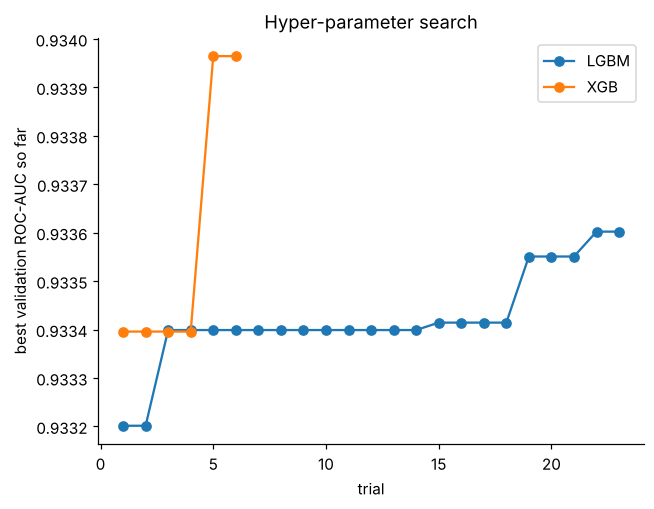

,model,trials,best validation AUC,trees
0,lgbm,23,0.9336,380
1,xgb,6,0.9340,718


In [11]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
db = f"sqlite:///{MODELS_DIR / 'optuna_tuning.db'}"
hist = []
for name in ["oulad_lgbm", "oulad_xgb"]:
    st = optuna.load_study(study_name=name, storage=db)
    tr = [x for x in st.trials if x.state.name == "COMPLETE"]
    hist.append((name.replace("oulad_", ""), len(tr), round(st.best_value, 4), st.best_trial.user_attrs.get("best_iteration")))
    vals = [x.value for x in tr]
    plt.plot(range(1, len(vals)+1), np.maximum.accumulate(vals), marker="o", label=name.replace("oulad_", "").upper())
plt.xlabel("trial"); plt.ylabel("best validation ROC-AUC so far"); plt.title("Hyper-parameter search"); plt.legend(); plt.show()
pd.DataFrame(hist, columns=["model", "trials", "best validation AUC", "trees"])

In [12]:
card = json.load(open(MODELS_DIR / "model_card.json"))
res = json.load(open(REPORTS_DIR / "oulad_results.json"))
print("Chosen on validation:", res["tuning"]["validation_auc_by_candidate"], "->", card["model"], "| threshold", round(card["threshold"], 3))
pd.Series(res["tuning"]["xgboost"]["params"], name="final XGBoost hyper-parameters").to_frame()

Chosen on validation: {'lightgbm': 0.9336022459409906, 'xgboost': 0.9339434358718833, 'ensemble': 0.9339345296825156} -> xgboost | threshold 0.505


,final XGBoost hyper-parameters
learning_rate,0.012152
max_depth,10.000000
min_child_weight,85.361899
subsample,0.904199
colsample_bytree,0.582768
reg_lambda,0.002459
reg_alpha,0.002978
gamma,2.200762


## 6. Accuracy — recomputed live from the saved model file
We load `models/oulad_completion_xgb.json` (the trained model), predict every task in the unseen **2014J** cohort,
and compute the metrics from scratch.

In [13]:
model_path = MODELS_DIR / "oulad_completion_xgb.json"
print("Model file:", model_path.name, "| size", f"{model_path.stat().st_size/1e6:.1f} MB",
      "| MD5", hashlib.md5(model_path.read_bytes()).hexdigest())
booster = xgb.Booster(); booster.load_model(str(model_path))
test = df[df.code_presentation == TEST_PRESENTATION].copy()
p = booster.predict(xgb.DMatrix(test[F], enable_categorical=True))
y = test.y.to_numpy(); yhat = (p >= 0.5).astype(int)
metrics = {"test samples": len(y), "accuracy": accuracy_score(y, yhat), "ROC-AUC": roc_auc_score(y, p),
           "macro F1": f1_score(y, yhat, average="macro"),
           "at-risk recall (late/missed caught)": recall_score(1-y, 1-yhat),
           "at-risk precision": precision_score(1-y, 1-yhat), "Brier score": brier_score_loss(y, p)}
pd.Series(metrics).round(4).to_frame("2014J (unseen)")

Model file: oulad_completion_xgb.json | size 13.2 MB | MD5 f713e4c22906fe183399639dbeea9e98


,2014J (unseen)
test samples,178124.0000
accuracy,0.8344
ROC-AUC,0.9155
macro F1,0.8343
at-risk recall (late/missed caught),0.8104
at-risk precision,0.8669
Brier score,0.1140


In [14]:
saved = res["test"]["FINAL_xgboost@0.5"]
print(f"Accuracy  live {metrics['accuracy']:.4f} | saved report {saved['accuracy']:.4f}")
print(f"ROC-AUC   live {metrics['ROC-AUC']:.4f} | saved report {saved['roc_auc']:.4f}")
assert abs(metrics["accuracy"] - saved["accuracy"]) < 1e-3, "live result differs from the saved report"
print("✔ the saved model reproduces the reported results")

Accuracy  live 0.8344 | saved report 0.8344
ROC-AUC   live 0.9155 | saved report 0.9155
✔ the saved model reproduces the reported results


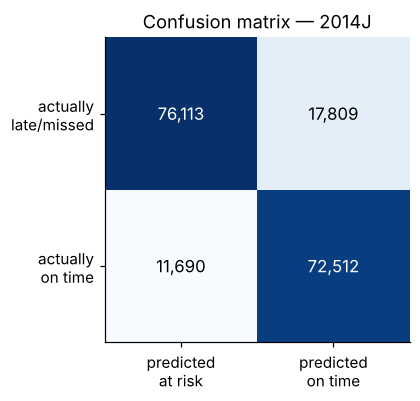

               precision    recall  f1-score   support

late / missed      0.867     0.810     0.838     93922
      on time      0.803     0.861     0.831     84202

     accuracy                          0.834    178124
    macro avg      0.835     0.836     0.834    178124
 weighted avg      0.837     0.834     0.835    178124



In [15]:
cm = confusion_matrix(y, yhat)
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max()/2 else "black", fontsize=11)
ax.set_xticks([0, 1], ["predicted\nat risk", "predicted\non time"]); ax.set_yticks([0, 1], ["actually\nlate/missed", "actually\non time"])
ax.set_title("Confusion matrix — 2014J"); plt.show()
print(classification_report(y, yhat, target_names=["late / missed", "on time"], digits=3))

## 7. Comparison with baselines, horizons, task types and calibration

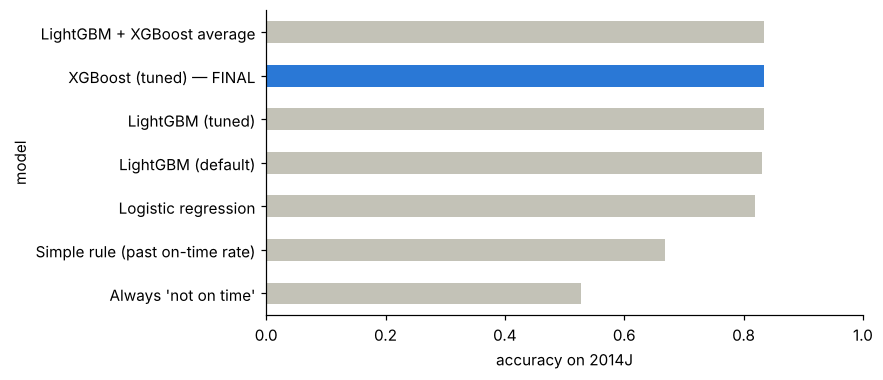

,model,accuracy,ROC-AUC,macro F1
6,LightGBM + XGBoost average,0.8346,0.9154,0.8345
5,XGBoost (tuned) — FINAL,0.8344,0.9155,0.8343
4,LightGBM (tuned),0.8339,0.9151,0.8338
3,LightGBM (default),0.8305,0.9132,0.8305
2,Logistic regression,0.8185,0.9003,0.8185
1,Simple rule (past on-time rate),0.6685,0.7658,0.6674
0,Always 'not on time',0.5273,0.5000,0.3452


In [16]:
names = {"majority_class": "Always 'not on time'", "rule_baseline": "Simple rule (past on-time rate)",
         "logistic_regression": "Logistic regression", "lightgbm_untuned": "LightGBM (default)",
         "lightgbm_tuned": "LightGBM (tuned)", "xgboost_tuned": "XGBoost (tuned) — FINAL", "ensemble_tuned": "LightGBM + XGBoost average"}
cmp = pd.DataFrame([(names[k], v["accuracy"], v["roc_auc"], v["macro_f1"]) for k, v in res["test"].items() if k in names],
                   columns=["model", "accuracy", "ROC-AUC", "macro F1"]).sort_values("accuracy")
ax = cmp.plot.barh(x="model", y="accuracy", legend=False, figsize=(7, 3.6), color=["#2a78d6" if "FINAL" in m else "#c3c2b7" for m in cmp.model])
ax.set_xlim(0, 1); ax.set_xlabel("accuracy on 2014J"); plt.show()
cmp.sort_values("accuracy", ascending=False).round(4)

In [17]:
rows = []
for h in HORIZONS:
    m = test.H.to_numpy() == h
    rows.append((f"{h} day(s) before", m.sum(), accuracy_score(y[m], yhat[m]), roc_auc_score(y[m], p[m])))
for name, v in (("TMA (tutor-marked)", 1), ("CMA (computer-marked)", 0)):
    m = test.is_tma.to_numpy() == v
    rows.append((name, m.sum(), accuracy_score(y[m], yhat[m]), roc_auc_score(y[m], p[m])))
pd.DataFrame(rows, columns=["subset", "samples", "accuracy", "ROC-AUC"]).round(4)

,subset,samples,accuracy,ROC-AUC
0,1 day(s) before,32383,0.8393,0.9176
1,3 day(s) before,44270,0.8375,0.9164
2,7 day(s) before,49033,0.8342,0.9112
3,14 day(s) before,52438,0.8290,0.9036
4,TMA (tutor-marked),129723,0.7941,0.8590
5,CMA (computer-marked),48401,0.9423,0.9744


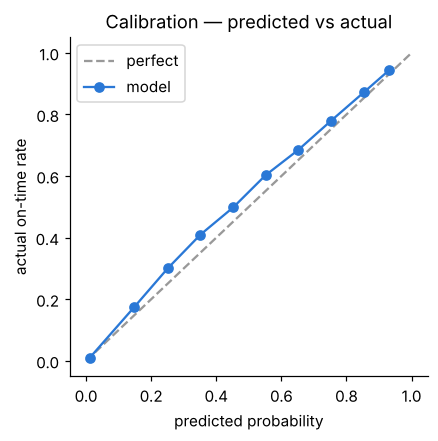

In [18]:
bins = np.linspace(0, 1, 11); idx = np.clip(np.digitize(p, bins) - 1, 0, 9)
mp = [p[idx == b].mean() for b in range(10) if (idx == b).any()]; my = [y[idx == b].mean() for b in range(10) if (idx == b).any()]
plt.figure(figsize=(4.2, 4)); plt.plot([0, 1], [0, 1], "--", color="#999", label="perfect")
plt.plot(mp, my, "o-", color="#2a78d6", label="model"); plt.xlabel("predicted probability"); plt.ylabel("actual on-time rate")
plt.title("Calibration — predicted vs actual"); plt.legend(); plt.show()

## 8. What drives the predictions
Mean absolute SHAP value per feature (exact tree SHAP from XGBoost) on 3,000 random test tasks.

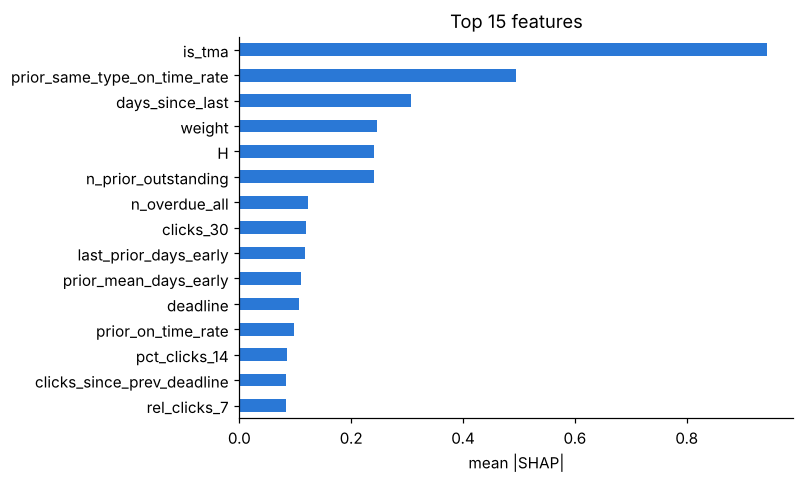

,mean |SHAP|
is_tma,0.944
prior_same_type_on_time_rate,0.494
days_since_last,0.307
weight,0.246
H,0.241
n_prior_outstanding,0.240
n_overdue_all,0.122
clicks_30,0.119
last_prior_days_early,0.118
prior_mean_days_early,0.111


In [19]:
smp = test.sample(3000, random_state=0)
contrib = booster.predict(xgb.DMatrix(smp[F], enable_categorical=True), pred_contribs=True)[:, :-1]
imp = pd.Series(np.abs(contrib).mean(0), index=F).sort_values(ascending=False).head(15)
imp[::-1].plot.barh(figsize=(6.5, 4.5), color="#2a78d6"); plt.xlabel("mean |SHAP|"); plt.title("Top 15 features"); plt.show()
imp.round(3).to_frame("mean |SHAP|")

## 9. Example predictions — input → output → what really happened
Five random tasks from the unseen 2014J cohort, showing the main inputs, the model's probability and the true outcome.

In [20]:
show = ["H", "is_tma", "weight", "prior_same_type_on_time_rate", "n_prior_outstanding", "days_since_last", "clicks_14", "n_overdue_all"]
ex = test.assign(p=p).sample(5, random_state=11)
out = ex[show].copy()
out["P(on time)"] = ex.p.round(3)
out["prediction"] = np.where(ex.p >= 0.5, "on time", "AT RISK")
out["actual"] = np.where(ex.y == 1, "on time", "late / missed")
out["correct?"] = np.where((ex.p >= 0.5) == (ex.y == 1), "✔", "✘")
out.reset_index(drop=True)

,H,is_tma,weight,prior_same_type_on_time_rate,n_prior_outstanding,days_since_last,clicks_14,n_overdue_all,P(on time),prediction,actual,correct?
0,3,1,9.0,NaN,0.0,4.0,240.0,0.0,0.445,AT RISK,late / missed,✔
1,3,1,25.0,0.75,0.0,1.0,13.0,0.0,0.720,on time,late / missed,✘
2,1,1,0.0,0.00,2.0,112.0,0.0,2.0,0.001,AT RISK,late / missed,✔
3,7,1,10.0,1.00,0.0,11.0,3.0,0.0,0.545,on time,on time,✔
4,14,0,0.0,NaN,0.0,0.0,211.0,0.0,0.703,on time,late / missed,✘


## 10. Independent leakage audit
`tests/research/test_no_leakage.py` re-derives features **directly from the raw CSV files** for random test rows and checks every
rule that keeps the evaluation honest (no future data, no forbidden columns, correct labels, disjoint cohorts, reproducible metrics).

In [21]:
import importlib.util
spec = importlib.util.spec_from_file_location("audit", Path.cwd().parent / "tests" / "research" / "test_no_leakage.py")
audit = importlib.util.module_from_spec(spec); spec.loader.exec_module(audit)
pkl = Path("/tmp/m3_samples_for_audit.pkl"); df.to_pickle(pkl)
ok = audit.main(str(pkl), str(REPORTS_DIR))
assert ok

[PASS] no forbidden columns in the model's features set()


[PASS] train and test cohorts are disjoint 
[PASS] no sample's task was already submitted at prediction time 
[PASS] every sample's student is registered at prediction time 
[PASS] label = submitted on or before deadline 


[PASS] click features match raw data up to day t only (300 random test rows) mismatches=0


[PASS] prior on-time counts match raw data (150 random test rows) mismatches=0


[PASS] saved test predictions reproduce reported accuracy acc=0.8339
[PASS] saved test predictions reproduce reported AUC auc=0.9155
[PASS] prediction file covers exactly the test cohort 
[PASS] shuffled labels give chance-level AUC (sanity) 
ALL CHECKS PASSED


## 11. Reproduce from scratch
```bash
cd services/m3-schedule-optimizer
pip install -e ../../contracts -r requirements-train.txt
export DATA_DIR=../../../07-datasets          # folder with oulad/raw/*.csv
PYTHONPATH=src python -m m3.train_oulad --lgbm-trials 30 --xgb-trials 20   # tune, train, evaluate (~1 h)
PYTHONPATH=src python -m m3.report_figures                                  # charts
python tests/research/test_no_leakage.py                                    # audit
jupyter nbconvert --to notebook --execute notebooks/01_completion_model_evidence.ipynb   # this notebook
```
**Limitation:** OULAD tasks are university assessments — a proxy for personal tasks. The method is validated here; the app model
is retrained on pilot-study task logs (recorded by the core API's task-event log).